# Trabajo Final — Tratamiento de Señales I
## Clasificación automática del tamaño de perros y similitud acústica por razas mediante MFCCs

**Objetivos:**
1. Realizar el análisis estadístico descriptivo e inferencial de la base de datos `DogsSpeakTDS`.
2. Construir una representación vectorial basada en bancos de filtros en escala Mel y coeficientes cepstrales (**MFCCs**) con ventana y solape configurables.
3. Generar vectores prototipo por tamaño (`Pequeño`, `Grande`) y por raza, analizando su concentración mediante pruebas estadísticas de hipótesis.
4. Evaluar la metodología sobre la base de datos propia (`10` perros, `3` ladridos por perro) y entregar una función autónoma capaz de predecir tamaño y porcentajes de similitud por raza para cualquier frecuencia de muestreo.


In [9]:
import os
import json
import wave
from math import gcd

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.fft import dct
from scipy.io import wavfile
from scipy.signal import get_window, resample_poly

# Detectar si se ejecuta en Google Colab o en entorno local
try:
    import google.colab
    from google.colab import drive
    drive.mount('/content/drive')
    # Ajusta esta ruta si subes la carpeta a otro lugar de tu Drive
    PROJECT_DIR = '/content/drive/MyDrive/Proyecto_Final_TDS1'
except ImportError:
    PROJECT_DIR = os.getcwd()
    if os.path.basename(PROJECT_DIR) != 'Proyecto_Final_TDS1' and os.path.isdir(os.path.join(PROJECT_DIR, 'Proyecto_Final_TDS1')):
        PROJECT_DIR = os.path.join(PROJECT_DIR, 'Proyecto_Final_TDS1')

METADATA_CSV = os.path.join(PROJECT_DIR, 'metadataDogsSpeakTDS.csv')
DOGSPEAK_DIR = os.path.join(PROJECT_DIR, 'DogSpeakTDS', 'DogSpeak_Seleccion')
OWN_DOGS_DIR = os.path.join(PROJECT_DIR, 'Ladridos y fotos perros')
ARTIFACTS_DIR = os.path.join(PROJECT_DIR, 'resultados')
PROTOTYPES_FILE = os.path.join(ARTIFACTS_DIR, 'prototipos_referencia.npz')
os.makedirs(ARTIFACTS_DIR, exist_ok=True)

print('PROJECT_DIR:', PROJECT_DIR)


PROJECT_DIR: c:\Users\Esteban Escamilla\Documents\UNIVERSIDAD\SEMESTRES\SEMESTRE 2026-2\TRATAMIENTO DE SEÑALES\PROYECTO FINAL\Proyecto_Final_TDS1


---
## 1. Base de datos `DogsSpeakTDS` y Análisis Estadístico

Definimos el criterio de tamaño para las 5 razas disponibles en `DogsSpeakTDS`:
* **Pequeños:** `chihuahua`, `shiba inu`
* **Grandes:** `german shepherd`, `husky`, `pitbull`

Aplicamos las herramientas vistas en el **Laboratorio 3**:
* Estadística descriptiva de metadatos, frecuencias de muestreo y duración de los audios.
* **Prueba $\chi^2$ de independencia** (`chi2_contingency`) sobre la tabla de contingencia entre **raza** y **sexo**.
* **Protocolo de comparación de dos grupos** (Shapiro-Wilk $\rightarrow$ Levene $\rightarrow$ *t-test* o *Mann-Whitney U*) para evaluar si la duración del ladrido cambia según el tamaño o el sexo.


In [10]:
BREED_TO_SIZE = {
    'chihuahua': 'Pequeño',
    'shiba inu': 'Pequeño',
    'german shepherd': 'Grande',
    'husky': 'Grande',
    'pitbull': 'Grande',
}
BREEDS = sorted(BREED_TO_SIZE.keys())
SIZES = ['Pequeño', 'Grande']

def load_dogspeak_metadata(csv_path=METADATA_CSV, audio_root=DOGSPEAK_DIR):
    df = pd.read_csv(csv_path)
    if 'Unnamed: 0' in df.columns:
        df = df.drop(columns=['Unnamed: 0'])
    wav_map = {}
    for dp, _, fns in os.walk(audio_root):
        for fn in fns:
            if fn.lower().endswith('.wav'):
                wav_map[fn] = os.path.join(dp, fn)
    df['filepath'] = df['filename'].map(wav_map)
    df['size'] = df['breed'].map(BREED_TO_SIZE)

    srs, durs = [], []
    for p in df['filepath']:
        with wave.open(p, 'rb') as w:
            sr = w.getframerate()
            dur = w.getnframes() / float(sr)
        srs.append(sr)
        durs.append(dur)
    df['sr'] = srs
    df['duration_s'] = durs
    return df

def compare_two_groups(group_a, group_b, name_a, name_b):
    _, p_norm_a = stats.shapiro(group_a)
    _, p_norm_b = stats.shapiro(group_b)
    both_normal = (p_norm_a > 0.05) and (p_norm_b > 0.05)
    _, p_levene = stats.levene(group_a, group_b)
    equal_var = p_levene > 0.05
    if both_normal:
        stat_val, p_val = stats.ttest_ind(group_a, group_b, equal_var=equal_var)
        test_name = 't-test Student' if equal_var else 't-test Welch'
    else:
        stat_val, p_val = stats.mannwhitneyu(group_a, group_b, alternative='two-sided')
        test_name = 'Mann-Whitney U'
    return {
        'grupo_a': name_a, 'grupo_b': name_b,
        'shapiro_p_a': p_norm_a, 'shapiro_p_b': p_norm_b,
        'levene_p': p_levene, 'prueba': test_name,
        'estadistico': stat_val, 'p_valor': p_val
    }

df = load_dogspeak_metadata()
print(f"Total grabaciones: {len(df)} | Perros únicos: {df['dog_id'].nunique()}")
print(f"Frecuencias de muestreo: {df['sr'].unique().tolist()} Hz")
print(df[['duration_s']].describe().T)
print("\nConteo por raza:\n", df['breed'].value_counts())
print("\nConteo por tamaño:\n", df['size'].value_counts())


Total grabaciones: 268 | Perros únicos: 122
Frecuencias de muestreo: [16000] Hz
            count      mean       std    min    25%    50%    75%     max
duration_s  268.0  1.449078  1.763446  0.064  0.448  0.896  1.728  15.552

Conteo por raza:
 breed
german shepherd    62
husky              56
pitbull            54
chihuahua          48
shiba inu          48
Name: count, dtype: int64

Conteo por tamaño:
 size
Grande     172
Pequeño     96
Name: count, dtype: int64


Tabla de contingencia Raza vs Sexo:


sex,female,male
breed,,
chihuahua,4,44
german shepherd,24,38
husky,40,16
pitbull,28,26
shiba inu,36,12


Chi-cuadrado = 58.8078, gl = 4, p-valor = 5.1639e-12

Duración Pequeño vs Grande: {'grupo_a': 'Pequeño', 'grupo_b': 'Grande', 'shapiro_p_a': np.float64(5.75669702763716e-16), 'shapiro_p_b': np.float64(2.8643254715615456e-18), 'levene_p': np.float64(0.8406804360409413), 'prueba': 'Mann-Whitney U', 'estadistico': np.float64(9135.0), 'p_valor': np.float64(0.14844286096500425)}
Duración Hembra vs Macho: {'grupo_a': 'Hembra', 'grupo_b': 'Macho', 'shapiro_p_a': np.float64(2.8176214690634378e-18), 'shapiro_p_b': np.float64(5.243698657682927e-16), 'levene_p': np.float64(0.5652028726437017), 'prueba': 'Mann-Whitney U', 'estadistico': np.float64(9440.0), 'p_valor': np.float64(0.4646578906491651)}


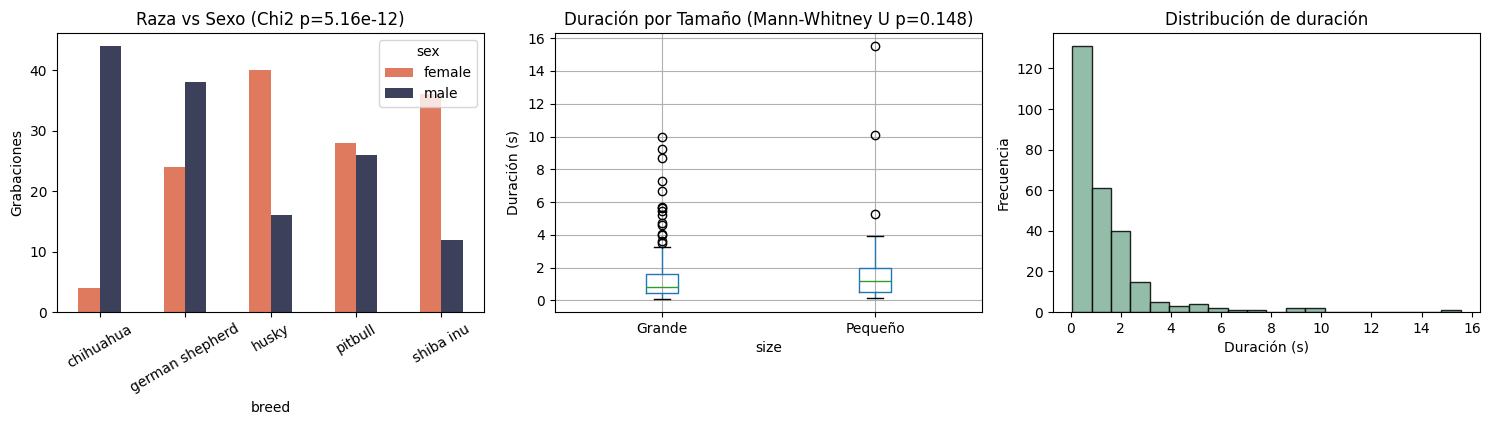

In [11]:
# Prueba Chi-cuadrado: Raza vs Sexo
ct_breed_sex = pd.crosstab(df['breed'], df['sex'])
chi2, p_chi2, dof, _ = stats.chi2_contingency(ct_breed_sex)
print("Tabla de contingencia Raza vs Sexo:")
display(ct_breed_sex)
print(f"Chi-cuadrado = {chi2:.4f}, gl = {dof}, p-valor = {p_chi2:.4e}")

# Comparación de duración por tamaño y por sexo
res_dur_size = compare_two_groups(
    df.loc[df['size'] == 'Pequeño', 'duration_s'].values,
    df.loc[df['size'] == 'Grande', 'duration_s'].values,
    'Pequeño', 'Grande'
)
res_dur_sex = compare_two_groups(
    df.loc[df['sex'] == 'female', 'duration_s'].values,
    df.loc[df['sex'] == 'male', 'duration_s'].values,
    'Hembra', 'Macho'
)
print("\nDuración Pequeño vs Grande:", res_dur_size)
print("Duración Hembra vs Macho:", res_dur_sex)

# Gráficas descriptivas
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
ct_breed_sex.plot(kind='bar', ax=axes[0], color=['#e07a5f', '#3d405b'])
axes[0].set_title(f'Raza vs Sexo (Chi2 p={p_chi2:.2e})')
axes[0].set_ylabel('Grabaciones')
axes[0].tick_params(axis='x', rotation=30)

df.boxplot(column='duration_s', by='size', ax=axes[1])
axes[1].set_title(f"Duración por Tamaño ({res_dur_size['prueba']} p={res_dur_size['p_valor']:.3f})")
axes[1].set_ylabel('Duración (s)')

axes[2].hist(df['duration_s'], bins=20, color='#81b29a', edgecolor='black', alpha=0.85)
axes[2].set_title('Distribución de duración')
axes[2].set_xlabel('Duración (s)')
axes[2].set_ylabel('Frecuencia')
plt.suptitle('')
plt.tight_layout()
plt.show()


---
## 2. Extracción de Características: Bancos de Filtros Mel y MFCCs

Siguiendo la **Unidad 4 (Escalado, Filtros y Bancos de Filtros)** y los **Laboratorios 4 y 5**, el proceso para convertir un audio de duración arbitraria en un vector de características fijo es:
1. **Carga, paso a mono, remoción DC y remuestreo** a $f_s = 16000\text{ Hz}$ (garantiza invariancia a la frecuencia de muestreo de entrada).
2. **Normalización de amplitud** e **enventanado Hamming** con parámetros configurables (`win_ms = 50 ms`, `overlap = 50%`).
3. **Selección de ventanas activas por energía (VAD)** (`vad_threshold = 0.05` respecto al pico): evita que los silencios antes o después del ladrido diluyan el promedio espectral.
4. **rFFT y espectro de potencia** $|X_m[k]|^2 / N_{\text{FFT}}$.
5. **Banco de filtros triangulares en escala Mel**:
   $$m(f) = 2595 \log_{10}\left(1 + \frac{f}{700}\right)$$
   Esta escala concentra mayor resolución en bajas y medias frecuencias, donde se diferencian las frecuencias fundamentales y formantes entre perros grandes y pequeños.
6. **Compresión logarítmica + DCT tipo II** $\rightarrow$ **MFCCs** por ventana, y **promedio temporal** para obtener un único vector por grabación.


In [12]:
# Parámetros configurables del extractor (puedes modificarlos aquí para experimentar)
FEATURE_PARAMS = {
    'target_sr': 16000,
    'win_ms': 50.0,       # Rango permitido: 20 - 250 ms
    'overlap': 0.50,      # Rango permitido: 0.10 - 0.50
    'window_type': 'hamming',
    'n_fft': 1024,
    'n_mels': 40,
    'n_mfcc': 13,
    'fmin': 50.0,
    'fmax': 8000.0,
    'include_c0': False,
    'vad_threshold': 0.05,
}

def hz_to_mel(f):
    return 2595.0 * np.log10(1.0 + np.asarray(f, dtype=np.float64) / 700.0)

def mel_to_hz(m):
    return 700.0 * (10.0 ** (np.asarray(m, dtype=np.float64) / 2595.0) - 1.0)

def load_and_resample(audio_path, target_sr=16000):
    sr, data = wavfile.read(audio_path)
    if np.issubdtype(data.dtype, np.integer):
        signal = data.astype(np.float64) / float(np.iinfo(data.dtype).max)
    else:
        signal = data.astype(np.float64)
    if signal.ndim > 1:
        signal = np.mean(signal, axis=1)
    signal = signal - np.mean(signal)
    if sr != target_sr:
        div = gcd(int(sr), int(target_sr))
        signal = resample_poly(signal, int(target_sr) // div, int(sr) // div)
    peak = np.max(np.abs(signal))
    if peak > 1e-12:
        signal = signal / peak
    return signal, target_sr

def create_mel_filterbank(sr, n_fft, n_mels=40, fmin=50.0, fmax=8000.0):
    fmax = min(fmax, sr / 2.0)
    mel_pts = np.linspace(hz_to_mel(fmin), hz_to_mel(fmax), n_mels + 2)
    hz_pts = mel_to_hz(mel_pts)
    bins = np.floor((n_fft + 1) * hz_pts / sr).astype(int)
    n_freqs = n_fft // 2 + 1
    fb = np.zeros((n_mels, n_freqs), dtype=np.float64)
    for m in range(1, n_mels + 1):
        l, c, r = bins[m - 1], bins[m], bins[m + 1]
        if c > l:
            for k in range(l, min(c, n_freqs)):
                fb[m - 1, k] = (k - l) / (c - l)
        if r > c:
            for k in range(max(c, 0), min(r, n_freqs)):
                fb[m - 1, k] = (r - k) / (r - c)
    enorm = 2.0 / np.maximum(hz_pts[2:n_mels + 2] - hz_pts[:n_mels], 1e-12)
    fb *= enorm[:, np.newaxis]
    return fb

def frame_signal(signal, sr, win_ms=50.0, overlap=0.50, window_type='hamming'):
    win_len = max(1, int(round((win_ms / 1000.0) * sr)))
    hop_len = max(1, int(round(win_len * (1.0 - overlap))))
    if len(signal) < win_len:
        signal = np.pad(signal, (0, win_len - len(signal)), mode='constant')
    n_frames = 1 + (len(signal) - win_len) // hop_len
    idx = np.arange(win_len)[None, :] + np.arange(n_frames)[:, None] * hop_len
    win = get_window(window_type, win_len, fftbins=True)
    return signal[idx] * win[None, :]

def extract_mfcc_vector(signal, sr, params=FEATURE_PARAMS, return_matrix=False):
    frames = frame_signal(signal, sr, params['win_ms'], params['overlap'], params['window_type'])
    if params['vad_threshold'] > 0.0:
        e = np.sum(frames ** 2, axis=1)
        m_e = np.max(e)
        if m_e > 1e-12:
            active = frames[e >= params['vad_threshold'] * m_e]
            if len(active) > 0:
                frames = active
    fft_size = max(params['n_fft'], 1 << (frames.shape[1] - 1).bit_length())
    spec = np.fft.rfft(frames, n=fft_size, axis=1)
    power = (np.abs(spec) ** 2) / fft_size
    fb = create_mel_filterbank(sr, fft_size, params['n_mels'], params['fmin'], params['fmax'])
    log_mel = np.log(np.maximum(np.dot(power, fb.T), 1e-12))
    mfcc_frames = dct(log_mel, type=2, axis=1, norm='ortho')
    s = 0 if params['include_c0'] else 1
    sel = mfcc_frames[:, s:s + params['n_mfcc']]
    vec = np.mean(sel, axis=0)
    return (vec, log_mel, sel) if return_matrix else vec


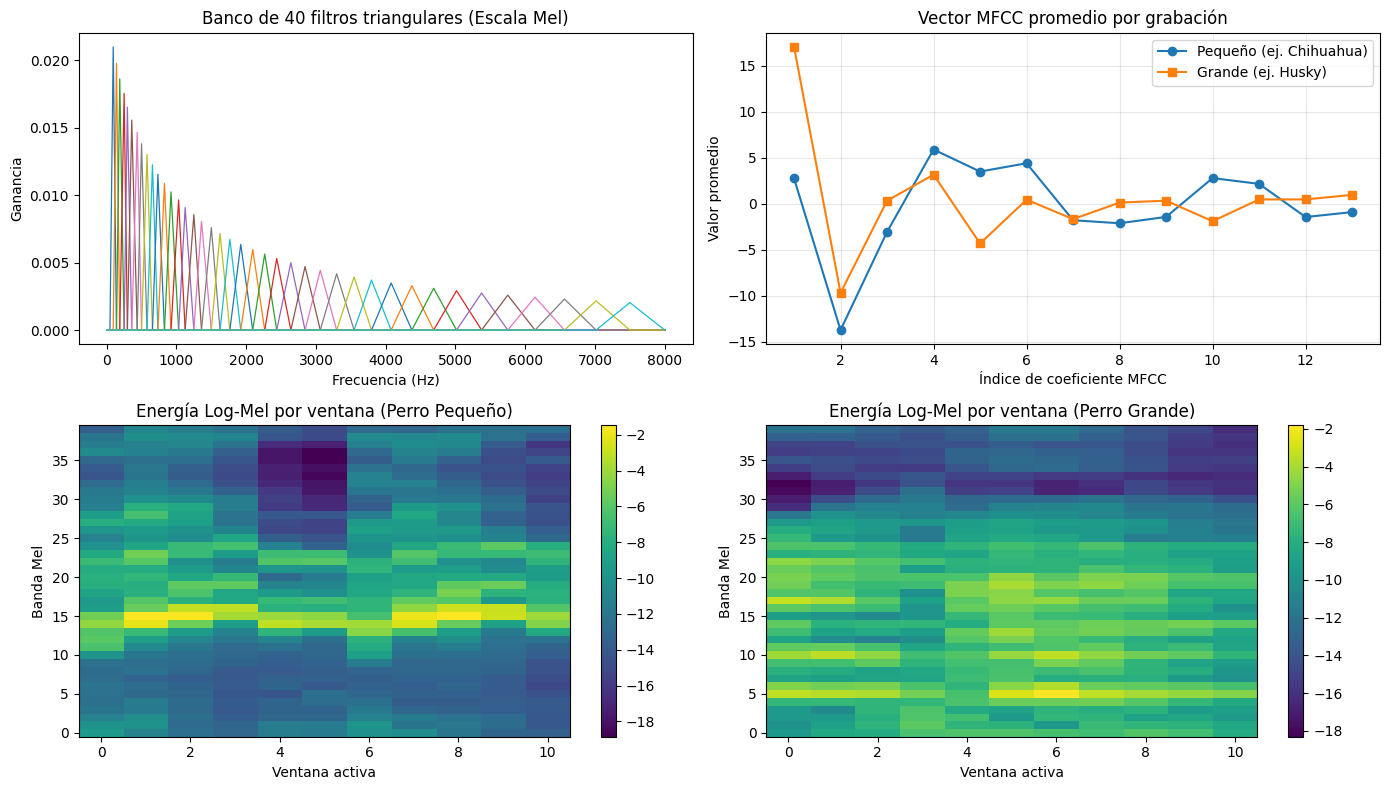

In [13]:
# Visualización del Banco de Filtros Mel y comparación visual: Perro Pequeño vs Perro Grande
fb_demo = create_mel_filterbank(16000, 1024, n_mels=FEATURE_PARAMS['n_mels'],
                                fmin=FEATURE_PARAMS['fmin'], fmax=FEATURE_PARAMS['fmax'])
freqs_hz = np.fft.rfftfreq(1024, 1 / 16000)

path_peq = df.loc[df['size'] == 'Pequeño', 'filepath'].iloc[0]
path_gra = df.loc[df['size'] == 'Grande', 'filepath'].iloc[0]

sig_p, sr_p = load_and_resample(path_peq, 16000)
sig_g, sr_g = load_and_resample(path_gra, 16000)
vec_p, logmel_p, mfcc_p = extract_mfcc_vector(sig_p, sr_p, FEATURE_PARAMS, return_matrix=True)
vec_g, logmel_g, mfcc_g = extract_mfcc_vector(sig_g, sr_g, FEATURE_PARAMS, return_matrix=True)

fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for m in range(fb_demo.shape[0]):
    axes[0, 0].plot(freqs_hz, fb_demo[m], linewidth=0.9)
axes[0, 0].set_title(f"Banco de {FEATURE_PARAMS['n_mels']} filtros triangulares (Escala Mel)")
axes[0, 0].set_xlabel('Frecuencia (Hz)')
axes[0, 0].set_ylabel('Ganancia')

axes[0, 1].plot(range(1, len(vec_p) + 1), vec_p, 'o-', label='Pequeño (ej. Chihuahua)')
axes[0, 1].plot(range(1, len(vec_g) + 1), vec_g, 's-', label='Grande (ej. Husky)')
axes[0, 1].set_title('Vector MFCC promedio por grabación')
axes[0, 1].set_xlabel('Índice de coeficiente MFCC')
axes[0, 1].set_ylabel('Valor promedio')
axes[0, 1].legend()
axes[0, 1].grid(alpha=0.3)

im1 = axes[1, 0].imshow(logmel_p.T, origin='lower', aspect='auto', cmap='viridis')
axes[1, 0].set_title('Energía Log-Mel por ventana (Perro Pequeño)')
axes[1, 0].set_xlabel('Ventana activa')
axes[1, 0].set_ylabel('Banda Mel')
fig.colorbar(im1, ax=axes[1, 0])

im2 = axes[1, 1].imshow(logmel_g.T, origin='lower', aspect='auto', cmap='viridis')
axes[1, 1].set_title('Energía Log-Mel por ventana (Perro Grande)')
axes[1, 1].set_xlabel('Ventana activa')
axes[1, 1].set_ylabel('Banda Mel')
fig.colorbar(im2, ax=axes[1, 1])

plt.tight_layout()
plt.show()


---
## 3. Vectores Prototipo, Análisis de Concentración y Guardado Autónomo

1. Extraemos el vector MFCC de las `268` grabaciones de `DogsSpeakTDS`.
2. Aplicamos **estandarización z-score** ($(x - \mu) / \sigma$) para que todos los coeficientes tengan igual peso en las métricas de similitud y distancia.
3. Calculamos los **2 prototipos de tamaño** (`Pequeño` y `Grande`) y los **5 prototipos por raza**.
4. Medimos la concentración de cada grabación alrededor de su prototipo usando **similitud coseno** y **distancia euclidiana ($L_2$)**, y aplicamos las pruebas de hipótesis del Lab 3.
5. Guardamos `mu`, `sigma`, prototipos y parámetros en `resultados/prototipos_referencia.npz`.


Concentración Similitud Coseno: {'grupo_a': 'Pequeño', 'grupo_b': 'Grande', 'shapiro_p_a': np.float64(0.15868002769165435), 'shapiro_p_b': np.float64(0.00010477765068342984), 'levene_p': np.float64(0.00018315473473577584), 'prueba': 'Mann-Whitney U', 'estadistico': np.float64(9124.0), 'p_valor': np.float64(0.15390189424906678)}
Concentración Distancia L2:    {'grupo_a': 'Pequeño', 'grupo_b': 'Grande', 'shapiro_p_a': np.float64(0.017263779114424838), 'shapiro_p_b': np.float64(0.002078180967770054), 'levene_p': np.float64(0.2514785715976054), 'prueba': 'Mann-Whitney U', 'estadistico': np.float64(8987.0), 'p_valor': np.float64(0.22986721576431635)}


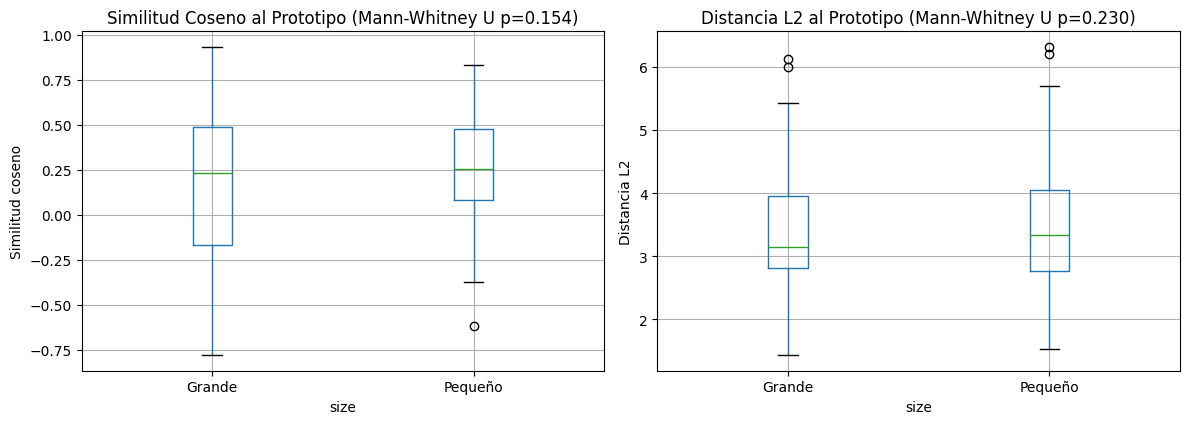

Prototipos guardados en: c:\Users\Esteban Escamilla\Documents\UNIVERSIDAD\SEMESTRES\SEMESTRE 2026-2\TRATAMIENTO DE SEÑALES\PROYECTO FINAL\Proyecto_Final_TDS1\resultados\prototipos_referencia.npz


In [14]:
X_raw = np.vstack([
    extract_mfcc_vector(*load_and_resample(p, FEATURE_PARAMS['target_sr']), FEATURE_PARAMS)
    for p in df['filepath']
])

mu = X_raw.mean(axis=0)
sigma = X_raw.std(axis=0) + 1e-12
X_std = (X_raw - mu) / sigma

size_prototypes = {sz: X_std[df['size'] == sz].mean(axis=0) for sz in SIZES}
breed_prototypes = {br: X_std[df['breed'] == br].mean(axis=0) for br in BREEDS}

def cos_sim(a, b):
    return float(np.dot(a, b) / ((np.linalg.norm(a) * np.linalg.norm(b)) + 1e-12))

df['cos_to_proto'] = [cos_sim(X_std[i], size_prototypes[sz]) for i, sz in enumerate(df['size'])]
df['dist_to_proto'] = [float(np.linalg.norm(X_std[i] - size_prototypes[sz])) for i, sz in enumerate(df['size'])]

res_cos = compare_two_groups(
    df.loc[df['size'] == 'Pequeño', 'cos_to_proto'].values,
    df.loc[df['size'] == 'Grande', 'cos_to_proto'].values,
    'Pequeño', 'Grande'
)
res_dist = compare_two_groups(
    df.loc[df['size'] == 'Pequeño', 'dist_to_proto'].values,
    df.loc[df['size'] == 'Grande', 'dist_to_proto'].values,
    'Pequeño', 'Grande'
)
print('Concentración Similitud Coseno:', res_cos)
print('Concentración Distancia L2:   ', res_dist)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
df.boxplot(column='cos_to_proto', by='size', ax=axes[0])
axes[0].set_title(f"Similitud Coseno al Prototipo ({res_cos['prueba']} p={res_cos['p_valor']:.3f})")
axes[0].set_ylabel('Similitud coseno')

df.boxplot(column='dist_to_proto', by='size', ax=axes[1])
axes[1].set_title(f"Distancia L2 al Prototipo ({res_dist['prueba']} p={res_dist['p_valor']:.3f})")
axes[1].set_ylabel('Distancia L2')
plt.suptitle('')
plt.tight_layout()
plt.show()

np.savez(
    PROTOTYPES_FILE,
    mu=mu,
    sigma=sigma,
    size_names=np.array(SIZES),
    size_vectors=np.vstack([size_prototypes[s] for s in SIZES]),
    breed_names=np.array(BREEDS),
    breed_vectors=np.vstack([breed_prototypes[b] for b in BREEDS]),
    feature_params_json=np.array(json.dumps(FEATURE_PARAMS)),
)
print('Prototipos guardados en:', PROTOTYPES_FILE)


---
## 4. Función Autónoma de Predicción (`predecir_ladrido`)

Esta función cumple el entregable final: recibe únicamente la ruta de un audio (con **cualquier frecuencia de muestreo**) y usa solo `prototipos_referencia.npz` sin acceder a las bases de datos originales.

Para expresar las similitudes con las 5 razas como porcentajes normalizados cuya suma sea $100\%$, aplicamos la función **Softmax** con temperatura $\tau$:
$$p_i = \frac{\exp(s_i / \tau)}{\sum_{j=1}^{5} \exp(s_j / \tau)} \times 100\%$$
donde $s_i$ es la similitud coseno con el prototipo de la raza $i$. Esta transformación garantiza $p_i > 0$, $\sum_i p_i = 100\%$ y preserva estrictamente el orden de similitud.


In [15]:
def softmax_percentages(similarities, temperature=0.25):
    scaled = (similarities - np.max(similarities)) / temperature
    exps = np.exp(scaled)
    return 100.0 * exps / np.sum(exps)

def predecir_ladrido(ruta_audio, prototypes_path=PROTOTYPES_FILE, temperature=0.25):
    data = np.load(prototypes_path, allow_pickle=False)
    mu = data['mu']
    sigma = data['sigma']
    size_names = data['size_names'].tolist()
    size_vectors = data['size_vectors']
    breed_names = data['breed_names'].tolist()
    breed_vectors = data['breed_vectors']
    params = json.loads(str(data['feature_params_json']))

    sig, sr = load_and_resample(ruta_audio, target_sr=params['target_sr'])
    x_raw = extract_mfcc_vector(sig, sr, params)
    x_std = (x_raw - mu) / sigma
    x_norm = np.linalg.norm(x_std) + 1e-12

    size_sims = {
        name: float(np.dot(x_std, vec) / (x_norm * (np.linalg.norm(vec) + 1e-12)))
        for name, vec in zip(size_names, size_vectors)
    }
    pred_size = max(size_sims, key=size_sims.get)

    breed_sims = np.array([
        float(np.dot(x_std, vec) / (x_norm * (np.linalg.norm(vec) + 1e-12)))
        for vec in breed_vectors
    ])
    breed_pcts = softmax_percentages(breed_sims, temperature=temperature)
    return {
        'tamano': pred_size,
        'similitud_tamano': size_sims,
        'porcentajes_razas': {n: round(float(p), 2) for n, p in zip(breed_names, breed_pcts)},
    }


---
## 5. Evaluación sobre tu Base de Datos Propia (`Ladridos y fotos perros`)

Recorre las subcarpetas `Grandes/<NombrePerro>/` y `Pequenos/<NombrePerro>/` (o `Pequeños/<NombrePerro>/`), evalúa los 3 ladridos de cada perro, calcula la **decisión única por animal** (promedio de similitudes de los 3 ladridos) y muestra la exactitud, matriz de confusión y porcentajes por raza.


In [16]:
rows = []
if os.path.isdir(OWN_DOGS_DIR):
    for size_folder in os.listdir(OWN_DOGS_DIR):
        size_path = os.path.join(OWN_DOGS_DIR, size_folder)
        if not os.path.isdir(size_path):
            continue
        true_size = 'Grande' if 'grand' in size_folder.lower() else 'Pequeño'
        for dog_name in sorted(os.listdir(size_path)):
            dog_path = os.path.join(size_path, dog_name)
            if not os.path.isdir(dog_path):
                continue
            wavs = sorted([
                f for f in os.listdir(dog_path)
                if f.lower().endswith('.wav') and 'ladrido roco' not in f.lower()
            ])
            for wf in wavs:
                res = predecir_ladrido(os.path.join(dog_path, wf))
                rows.append({
                    'perro': dog_name,
                    'archivo': wf,
                    'tamano_real': true_size,
                    'tamano_pred': res['tamano'],
                    'sim_pequeno': res['similitud_tamano']['Pequeño'],
                    'sim_grande': res['similitud_tamano']['Grande'],
                    **res['porcentajes_razas'],
                })

df_own = pd.DataFrame(rows)
if len(df_own) > 0:
    display(df_own)
    acc_audio = (df_own['tamano_real'] == df_own['tamano_pred']).mean()
    print(f"Exactitud por audio ({len(df_own)} audios): {acc_audio:.2%}")

    # Decisión única por perro: promedio de similitud coseno sobre sus 3 ladridos
    df_dog = df_own.groupby(['perro', 'tamano_real'], as_index=False).mean(numeric_only=True)
    df_dog['decision_perro'] = np.where(df_dog['sim_grande'] >= df_dog['sim_pequeno'], 'Grande', 'Pequeño')
    acc_dog = (df_dog['tamano_real'] == df_dog['decision_perro']).mean()
    print(f"Exactitud por perro ({len(df_dog)} perros): {acc_dog:.2%}")
    display(df_dog[['perro', 'tamano_real', 'decision_perro'] + BREEDS])

    # Matriz de confusión por perro
    cm = pd.crosstab(df_dog['tamano_real'], df_dog['decision_perro'], rownames=['Real'], colnames=['Predicho'])
    display(cm)
else:
    print('Aún no hay audios evaluables en:', OWN_DOGS_DIR)


,perro,archivo,tamano_real,tamano_pred,sim_pequeno,sim_grande,chihuahua,german shepherd,husky,pitbull,shiba inu
0,Rocco,rocco_ladrido_1.wav,Grande,Grande,-0.408006,0.408006,3.15,20.16,55.88,19.07,1.74
1,Rocco,rocco_ladrido_2.wav,Grande,Grande,-0.380739,0.380739,3.40,25.86,47.89,20.18,2.66
2,Rocco,rocco_ladrido_3.wav,Grande,Grande,-0.257243,0.257243,7.04,14.60,45.09,29.36,3.90


Exactitud por audio (3 audios): 100.00%
Exactitud por perro (1 perros): 100.00%


,perro,tamano_real,decision_perro,chihuahua,german shepherd,husky,pitbull,shiba inu
0,Rocco,Grande,Grande,4.53,20.206667,49.62,22.87,2.766667


Predicho,Grande
Real,
Grande,1
